In [9]:
from __future__ import annotations

import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


ROOT =  Path(r"C:\Users\kdmsw\Desktop\Projects\name_that_llm")

DATA_PATH = ROOT / "data" / "train.csv"
OUTPUT_DIR = ROOT / "artifacts" / "eda"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
plt.style.use("seaborn-v0_8-whitegrid")
COLORS = plt.cm.tab20(np.linspace(0, 1, 20))


def finish_figure(name: str) -> None:
    """Apply consistent layout, save a figure, and display it."""
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()



In [10]:
df = pd.read_csv(DATA_PATH)
required_columns = {"id", "prompt_id", "text", "model"}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Models: {df['model'].nunique():,}")
print(f"Prompts: {df['prompt_id'].nunique():,}")
print("\nMissing values:\n", df.isna().sum())
print("\nExact duplicate texts:", int(df["text"].duplicated().sum()))
print("Duplicate IDs:", int(df["id"].duplicated().sum()))
display(df.head()) if "display" in globals() else print(df.head())

Shape: 2,699 rows x 4 columns
Models: 18
Prompts: 150

Missing values:
 id           0
prompt_id    0
text         0
model        0
dtype: int64

Exact duplicate texts: 0
Duplicate IDs: 0
             id prompt_id                                               text             model
0  0018b3765972      p081  When a language dies, a particular astronomy d...       qwen3.8-max
1  0041ac86ee93      p073  Data science communities matter because they a...   claude-sonnet-5
2  005a19083eae      p120  In the final twilight of time, the last embers...  gemini-3.6-flash
3  009319596f10      p073  Data science communities matter because they t...     gpt-5.6-terra
4  00d3e8c92596      p097  Deep inside each ear, three tiny loops of bone...     glm-5.3-flash


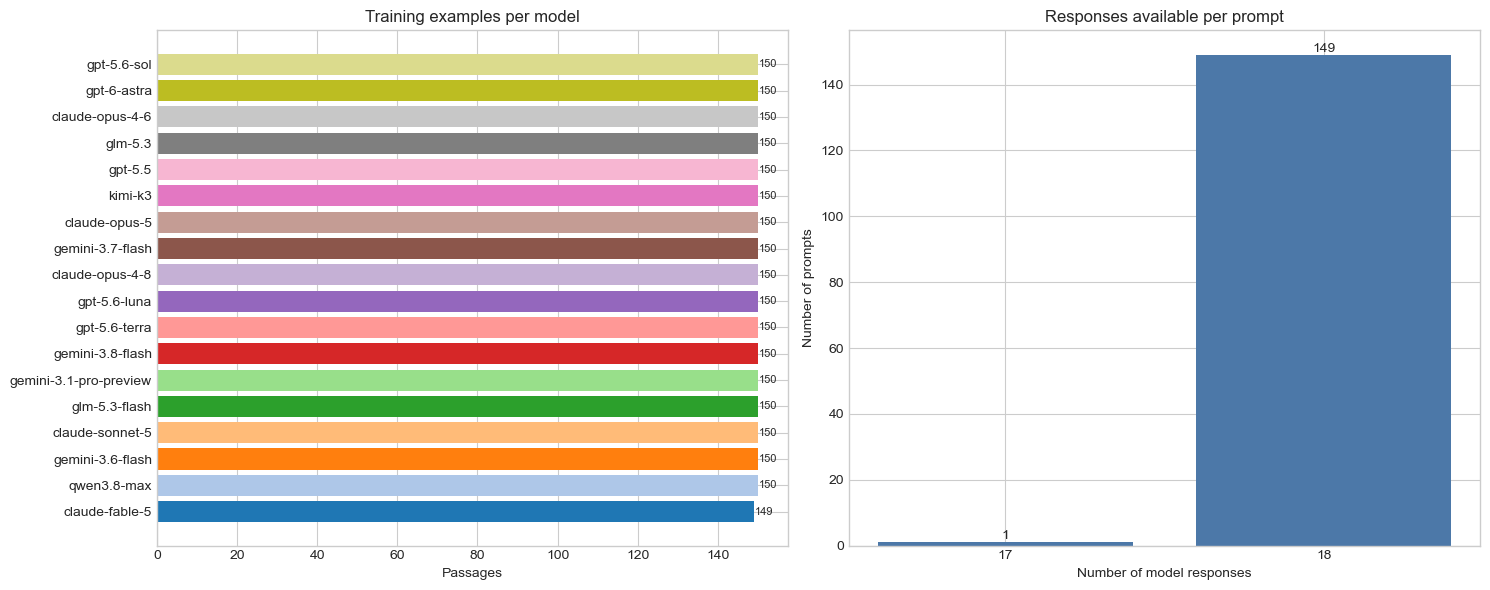

In [11]:
# %% Dataset overview
model_counts = df["model"].value_counts().sort_values()
prompt_sizes = df.groupby("prompt_id").size()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(model_counts.index, model_counts.values, color=COLORS[: len(model_counts)])
axes[0].set_title("Training examples per model")
axes[0].set_xlabel("Passages")
for idx, value in enumerate(model_counts.values):
    axes[0].text(value + 0.15, idx, str(value), va="center", fontsize=8)

size_counts = prompt_sizes.value_counts().sort_index()
axes[1].bar(size_counts.index.astype(str), size_counts.values, color="#4C78A8")
axes[1].set_title("Responses available per prompt")
axes[1].set_xlabel("Number of model responses")
axes[1].set_ylabel("Number of prompts")
for idx, value in enumerate(size_counts.values):
    axes[1].text(idx, value + 1, str(value), ha="center")
finish_figure("01_dataset_overview")

Missing model-prompt combinations:
         model prompt_id
claude-fable-5      p002


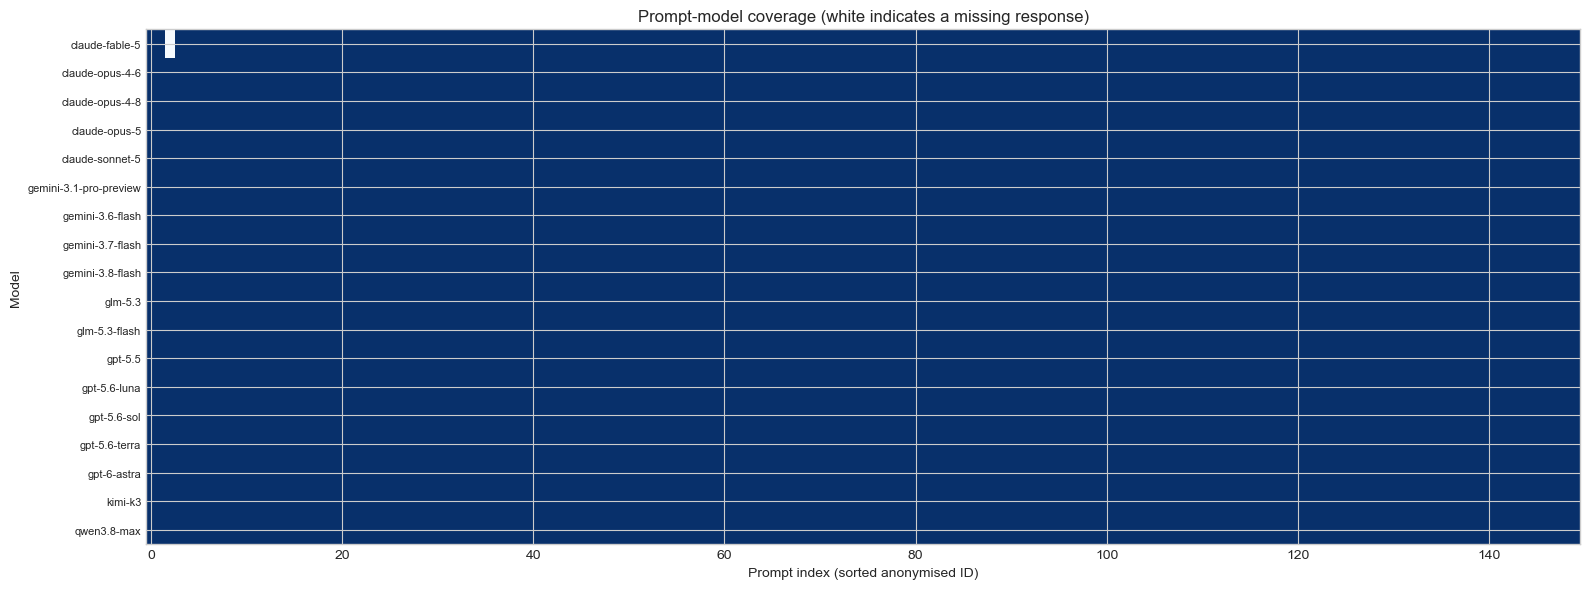

In [12]:
coverage = pd.crosstab(df["model"], df["prompt_id"])
missing_pairs = (
    coverage.eq(0)
    .stack()
    .loc[lambda values: values]
    .index.to_frame(index=False, name=["model", "prompt_id"])
)
print("Missing model-prompt combinations:")
print(missing_pairs.to_string(index=False) if len(missing_pairs) else "None")

fig, ax = plt.subplots(figsize=(16, 6))
ax.imshow(coverage.values, aspect="auto", interpolation="nearest", cmap="Blues", vmin=0, vmax=1)
ax.set_title("Prompt-model coverage (white indicates a missing response)")
ax.set_xlabel("Prompt index (sorted anonymised ID)")
ax.set_ylabel("Model")
ax.set_yticks(range(len(coverage.index)))
ax.set_yticklabels(coverage.index, fontsize=8)
finish_figure("02_prompt_model_coverage")

In [13]:
def count_pattern(text: str, pattern: str) -> int:
    return len(re.findall(pattern, text, flags=re.MULTILINE))


features = pd.DataFrame(index=df.index)
features["characters"] = df["text"].str.len()
features["words"] = df["text"].str.findall(r"\b\w+\b").str.len()
features["sentences"] = df["text"].str.count(r"[.!?](?:\s|$)").clip(lower=1)
features["paragraphs"] = df["text"].str.count(r"\n\s*\n") + 1
features["avg_word_length"] = features["characters"] / features["words"].clip(lower=1)
features["avg_sentence_words"] = features["words"] / features["sentences"]
features["unique_word_ratio"] = df["text"].map(
    lambda value: len(set(re.findall(r"\b\w+\b", value.lower())))
    / max(1, len(re.findall(r"\b\w+\b", value.lower())))
)
features["newlines"] = df["text"].str.count("\n")
features["commas"] = df["text"].str.count(",")
features["semicolons"] = df["text"].str.count(";")
features["colons"] = df["text"].str.count(":")
features["question_marks"] = df["text"].str.count(r"\?")
features["exclamation_marks"] = df["text"].str.count("!")
features["parentheses"] = df["text"].str.count(r"[()]" )
features["em_dashes"] = df["text"].str.count("—")
features["markdown_bold"] = df["text"].str.count(r"\*\*") // 2
features["headings"] = df["text"].map(lambda value: count_pattern(value, r"^#{1,6}\s"))
features["list_items"] = df["text"].map(lambda value: count_pattern(value, r"^\s*(?:[-*+] |\d+[.)] )"))
features["code_fences"] = df["text"].str.count("```") // 2
features["latex_markers"] = df["text"].str.count(r"\$|\\\(|\\\[|\\begin\{")
features["uppercase_ratio"] = df["text"].map(
    lambda value: sum(char.isupper() for char in value) / max(1, sum(char.isalpha() for char in value))
)

eda = pd.concat([df, features], axis=1)
print(features.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T.round(2))


                     count    mean     std     min      5%     25%     50%      75%      95%      max
characters          2699.0  755.29  377.37  230.00  297.00  429.00  670.00  1027.00  1469.20  1900.00
words               2699.0  116.69   59.09   37.00   45.90   66.00  103.00   161.00   228.00   279.00
sentences           2699.0    4.84    2.16    1.00    2.00    3.00    5.00     6.00     9.00    14.00
paragraphs          2699.0    1.00    0.00    1.00    1.00    1.00    1.00     1.00     1.00     1.00
avg_word_length     2699.0    6.52    0.53    4.94    5.71    6.15    6.48     6.85     7.47     8.52
avg_sentence_words  2699.0   24.59   10.72    9.20   15.71   20.00   23.33    27.00    35.25   226.00
unique_word_ratio   2699.0    0.82    0.08    0.49    0.68    0.76    0.82     0.89     0.95     1.00
newlines            2699.0    0.00    0.00    0.00    0.00    0.00    0.00     0.00     0.00     0.00
commas              2699.0   10.36    5.72    0.00    3.00    6.00    9.00    14.0

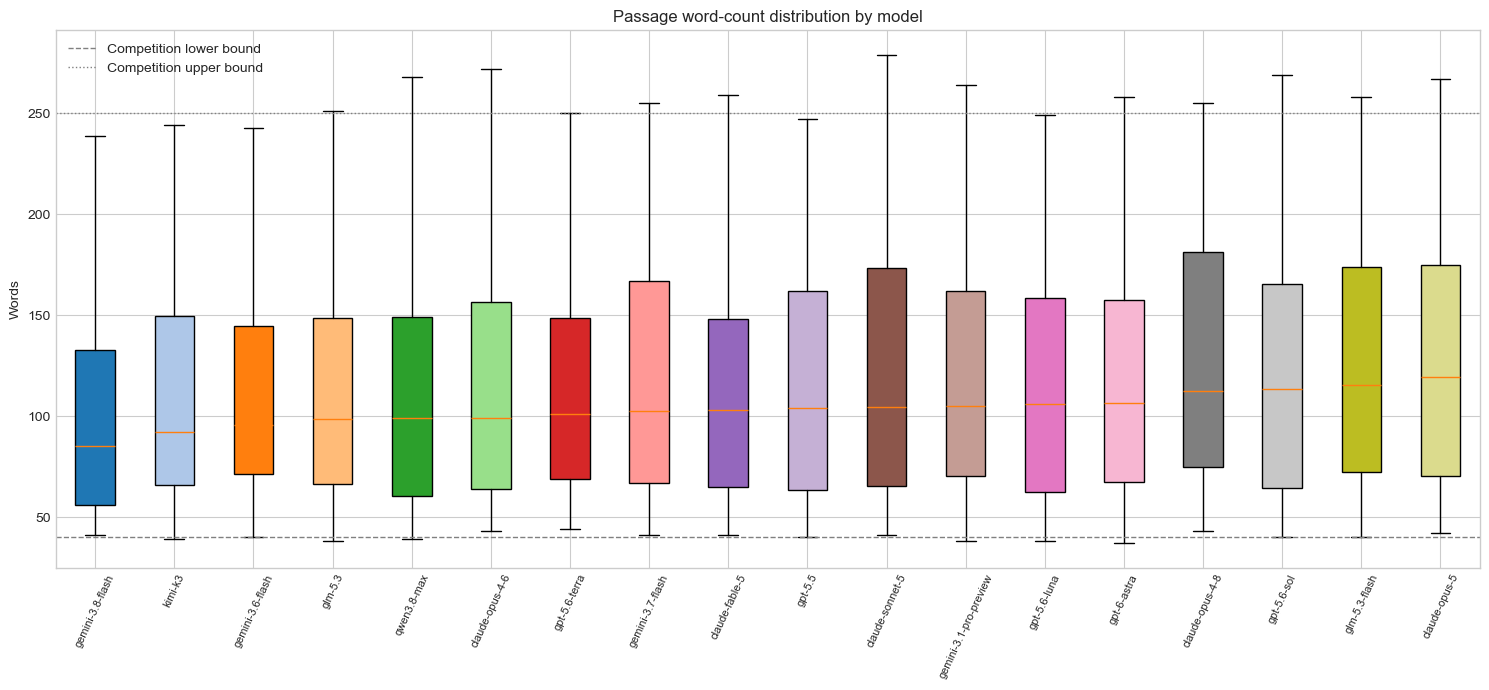

In [14]:
ordered_models = eda.groupby("model")["words"].median().sort_values().index
length_data = [eda.loc[eda["model"].eq(model), "words"] for model in ordered_models]

fig, ax = plt.subplots(figsize=(15, 7))
box = ax.boxplot(length_data, tick_labels=ordered_models, patch_artist=True, showfliers=False)
for patch, color in zip(box["boxes"], COLORS):
    patch.set_facecolor(color)
ax.axhline(40, color="grey", linestyle="--", linewidth=1, label="Competition lower bound")
ax.axhline(250, color="grey", linestyle=":", linewidth=1, label="Competition upper bound")
ax.set_title("Passage word-count distribution by model")
ax.set_ylabel("Words")
ax.tick_params(axis="x", rotation=65, labelsize=8)
ax.legend()
finish_figure("03_word_count_by_model")

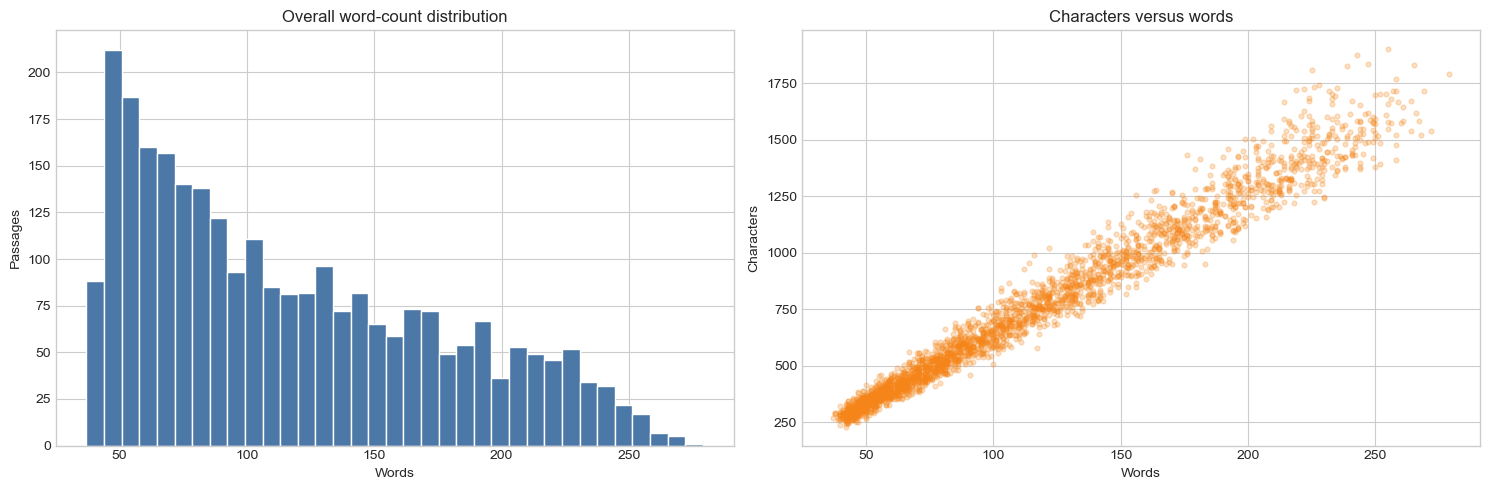

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].hist(eda["words"], bins=35, color="#4C78A8", edgecolor="white")
axes[0].set_title("Overall word-count distribution")
axes[0].set_xlabel("Words")
axes[0].set_ylabel("Passages")

axes[1].scatter(eda["words"], eda["characters"], alpha=0.25, s=12, color="#F58518")
axes[1].set_title("Characters versus words")
axes[1].set_xlabel("Words")
axes[1].set_ylabel("Characters")
finish_figure("04_length_distribution")

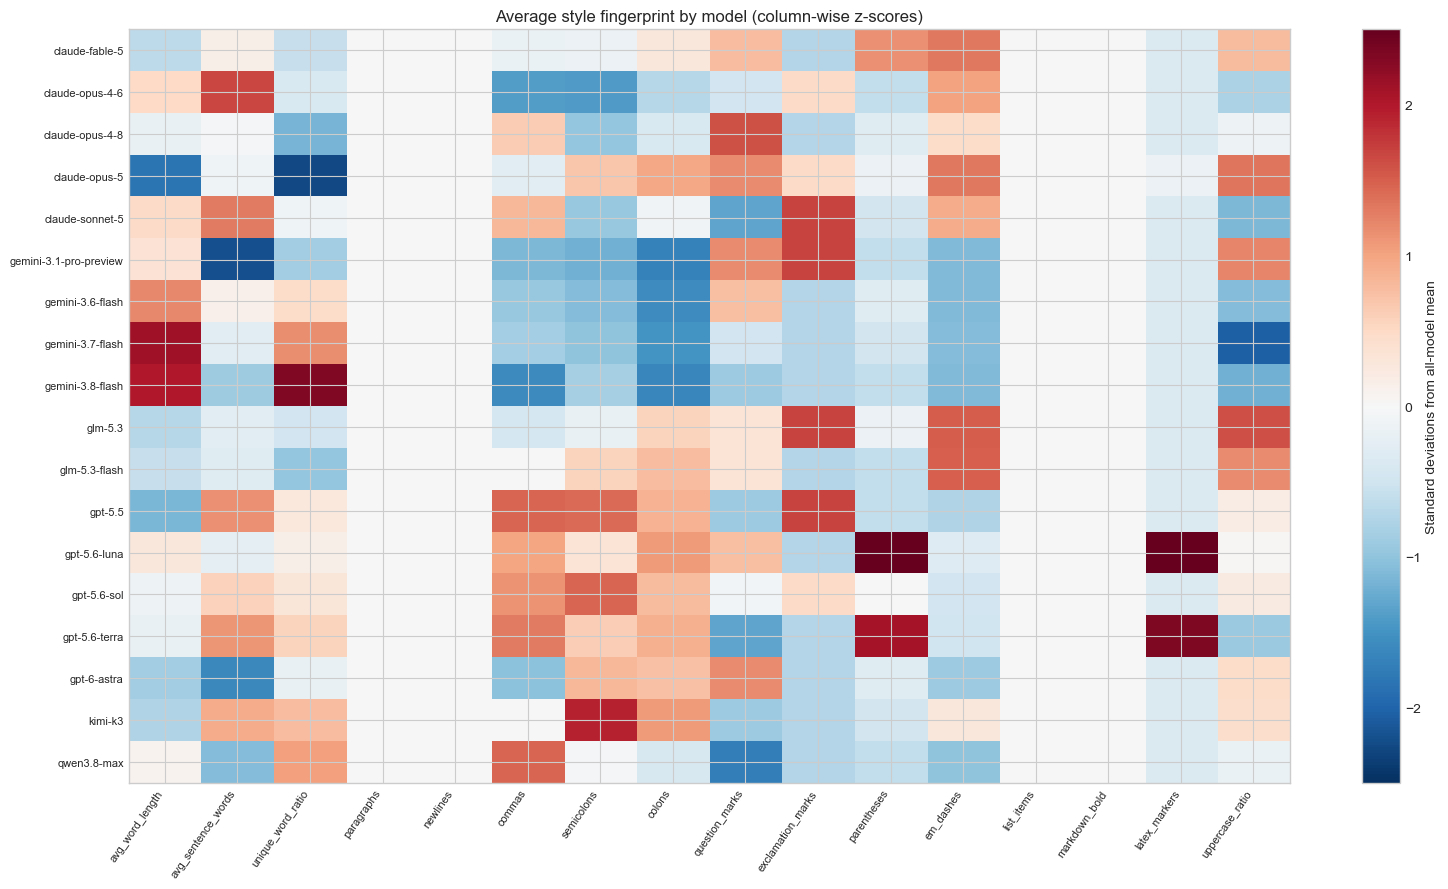

In [16]:
fingerprint_columns = [
    "avg_word_length", "avg_sentence_words", "unique_word_ratio", "paragraphs",
    "newlines", "commas", "semicolons", "colons", "question_marks",
    "exclamation_marks", "parentheses", "em_dashes", "list_items",
    "markdown_bold", "latex_markers", "uppercase_ratio",
]
model_fingerprints = eda.groupby("model")[fingerprint_columns].mean()
z_scores = (model_fingerprints - model_fingerprints.mean()) / model_fingerprints.std(ddof=0).replace(0, 1)

fig, ax = plt.subplots(figsize=(16, 9))
image = ax.imshow(z_scores.values, aspect="auto", cmap="RdBu_r", vmin=-2.5, vmax=2.5)
ax.set_xticks(range(len(z_scores.columns)))
ax.set_xticklabels(z_scores.columns, rotation=55, ha="right", fontsize=8)
ax.set_yticks(range(len(z_scores.index)))
ax.set_yticklabels(z_scores.index, fontsize=8)
ax.set_title("Average style fingerprint by model (column-wise z-scores)")
fig.colorbar(image, ax=ax, label="Standard deviations from all-model mean")
finish_figure("05_style_fingerprint_heatmap")

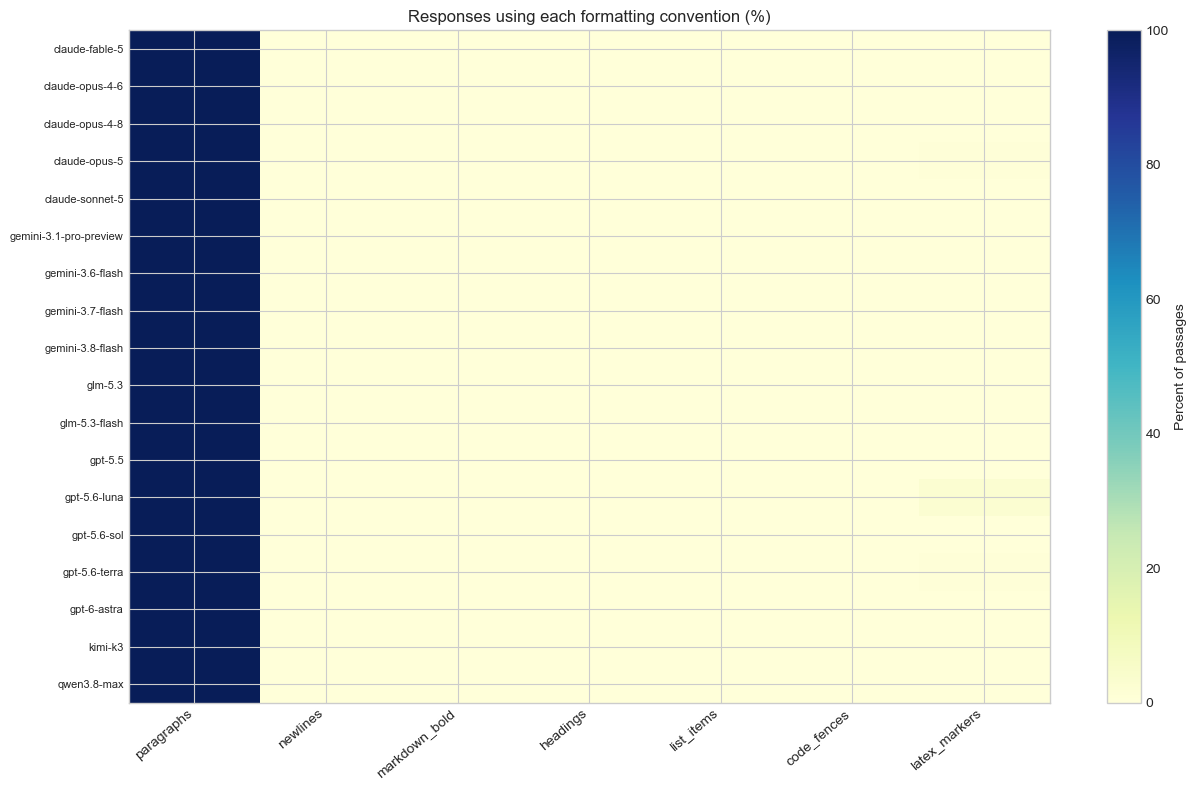

In [17]:
binary_format_features = ["paragraphs", "newlines", "markdown_bold", "headings", "list_items", "code_fences", "latex_markers"]
presence = eda[binary_format_features].gt(0).join(eda["model"]).groupby("model").mean().mul(100)

fig, ax = plt.subplots(figsize=(13, 8))
image = ax.imshow(presence.values, aspect="auto", cmap="YlGnBu", vmin=0, vmax=max(1, presence.to_numpy().max()))
ax.set_xticks(range(len(presence.columns)))
ax.set_xticklabels(presence.columns, rotation=40, ha="right")
ax.set_yticks(range(len(presence.index)))
ax.set_yticklabels(presence.index, fontsize=8)
ax.set_title("Responses using each formatting convention (%)")
fig.colorbar(image, ax=ax, label="Percent of passages")
finish_figure("06_formatting_usage")

In [18]:
def opening_phrase(text: str, words: int = 3) -> str:
    tokens = re.findall(r"[A-Za-z]+(?:'[A-Za-z]+)?", text.lower())
    return " ".join(tokens[:words]) if tokens else "<no alphabetic opening>"


eda["opening_3gram"] = eda["text"].map(opening_phrase)
opening_rows = []
for model, group in eda.groupby("model"):
    for phrase, count in group["opening_3gram"].value_counts().head(3).items():
        opening_rows.append({"model": model, "opening": phrase, "count": count})
top_openings = pd.DataFrame(opening_rows).sort_values(["model", "count"], ascending=[True, False])
print("\nThree most common three-word openings per model:\n")
print(top_openings.to_string(index=False))


Three most common three-word openings per model:

                 model                   opening  count
        claude-fable-5               in the hush      2
        claude-fable-5        beneath the forest      2
        claude-fable-5             at the planck      1
       claude-opus-4-6                there is a      2
       claude-opus-4-6              it begins as      2
       claude-opus-4-6          deep beneath the      2
       claude-opus-4-8                there is a      2
       claude-opus-4-8               in the vast      2
       claude-opus-4-8       when famine hollows      1
         claude-opus-5                there is a      3
         claude-opus-5         two miles beneath      3
         claude-opus-5            empty space is      2
       claude-sonnet-5               in the hush      3
       claude-sonnet-5           deep within the      2
       claude-sonnet-5               born in the      2
gemini-3.1-pro-preview           deep within the     

In [19]:
TOKEN_PATTERN = re.compile(r"[A-Za-z]+(?:'[A-Za-z]+)?")
documents = [set(TOKEN_PATTERN.findall(text.lower())) for text in df["text"]]
global_document_frequency = Counter(token for document in documents for token in document)
vocabulary = {token for token, count in global_document_frequency.items() if count >= 5}


def distinctive_tokens(model: str, top_n: int = 12) -> list[tuple[str, float]]:
    in_model = [documents[idx] for idx in df.index[df["model"].eq(model)]]
    out_model = [documents[idx] for idx in df.index[~df["model"].eq(model)]]
    in_counts = Counter(token for document in in_model for token in document)
    out_counts = Counter(token for document in out_model for token in document)
    n_in, n_out = len(in_model), len(out_model)
    scores = {
        token: np.log((in_counts[token] + 0.5) / (n_in - in_counts[token] + 0.5))
        - np.log((out_counts[token] + 0.5) / (n_out - out_counts[token] + 0.5))
        for token in vocabulary
    }
    return sorted(scores.items(), key=lambda item: item[1], reverse=True)[:top_n]


distinctive = {
    model: ", ".join(token for token, _ in distinctive_tokens(model))
    for model in sorted(df["model"].unique())
}
print("\nCandidate distinctive tokens (validate with grouped CV before modeling):\n")
for model, tokens in distinctive.items():
    print(f"{model:24s} {tokens}")


Candidate distinctive tokens (validate with grouped CV before modeling):

claude-fable-5           legitimate, slice, counter, pouring, smoothing, forgery, default, totality, discourse, attempted, imagines, foragers
claude-opus-4-6          comfortable, converges, authored, cathedrals, stunning, inhabits, levels, flooding, we've, splintered, willingness, textbooks
claude-opus-4-8          illuminate, wheeling, wield, mature, feathered, imaginable, lavender, compose, unused, fragrance, tomorrow's, retreat
claude-opus-5            anyway, confusion, poisoned, densely, maybe, gift, forty, one's, bite, breakfast, fatigue, rows
claude-sonnet-5          tally, representing, blurs, selfhood, conjured, watchful, minimal, seeming, atop, embodies, colonies, separately
gemini-3.1-pro-preview   washing, teeming, entities, societal, perfected, limitless, traditional, pulsating, agonizingly, ensures, puzzles, armed
gemini-3.6-flash         regarding, insurmountable, dominance, gloom, shedding, temp


Within-prompt word-count percentile by model:
                          mean  median    std
model                                       
gemini-3.8-flash        0.440   0.444  0.281
kimi-k3                 0.492   0.500  0.267
qwen3.8-max             0.496   0.500  0.291
gpt-5.5                 0.513   0.500  0.291
gemini-3.6-flash        0.518   0.486  0.276
glm-5.3                 0.525   0.556  0.290
gpt-5.6-luna            0.528   0.556  0.296
claude-fable-5          0.530   0.500  0.283
claude-opus-4-6         0.531   0.500  0.276
gpt-5.6-terra           0.533   0.500  0.260
gemini-3.7-flash        0.534   0.528  0.291
gpt-5.6-sol             0.538   0.556  0.291
claude-sonnet-5         0.538   0.556  0.311
gpt-6-astra             0.542   0.556  0.288
gemini-3.1-pro-preview  0.549   0.556  0.288
claude-opus-5           0.561   0.556  0.312
glm-5.3-flash           0.565   0.611  0.284
claude-opus-4-8         0.568   0.583  0.295


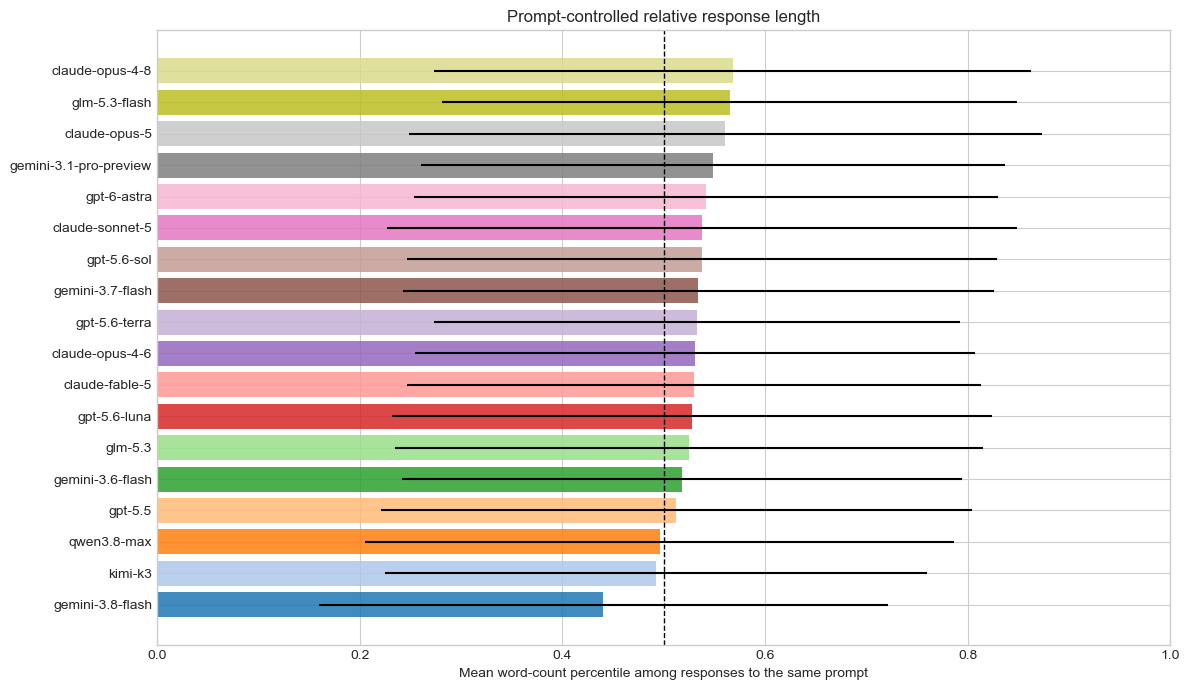

In [20]:
eda["word_count_prompt_percentile"] = eda.groupby("prompt_id")["words"].rank(pct=True)
rank_summary = eda.groupby("model")["word_count_prompt_percentile"].agg(["mean", "median", "std"]).sort_values("mean")
print("\nWithin-prompt word-count percentile by model:\n", rank_summary.round(3))

fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(rank_summary.index, rank_summary["mean"], xerr=rank_summary["std"], color=COLORS[: len(rank_summary)], alpha=0.85)
ax.axvline(0.5, color="black", linestyle="--", linewidth=1)
ax.set_xlim(0, 1)
ax.set_xlabel("Mean word-count percentile among responses to the same prompt")
ax.set_title("Prompt-controlled relative response length")
finish_figure("07_within_prompt_length_rank")

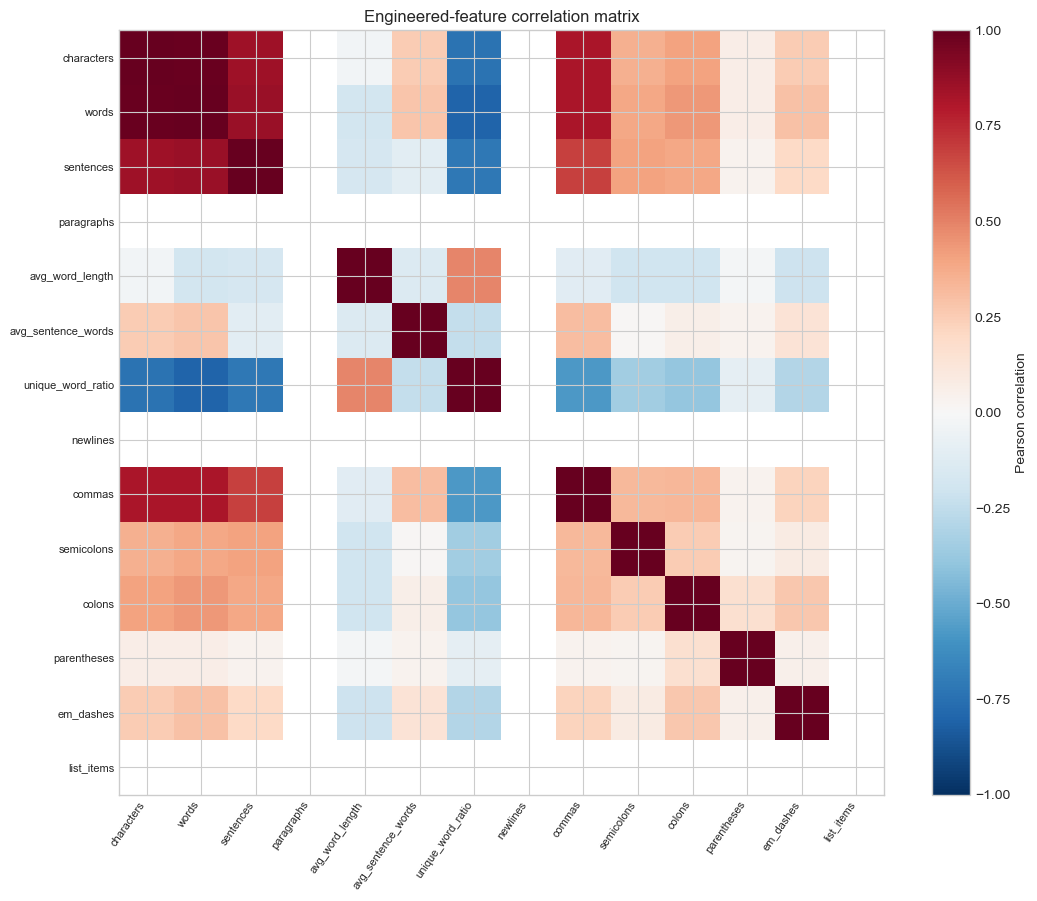

In [21]:
correlation_columns = [
    "characters", "words", "sentences", "paragraphs", "avg_word_length",
    "avg_sentence_words", "unique_word_ratio", "newlines", "commas",
    "semicolons", "colons", "parentheses", "em_dashes", "list_items",
]
correlations = eda[correlation_columns].corr()

fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(correlations.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlations.columns)))
ax.set_xticklabels(correlations.columns, rotation=55, ha="right", fontsize=8)
ax.set_yticks(range(len(correlations.index)))
ax.set_yticklabels(correlations.index, fontsize=8)
ax.set_title("Engineered-feature correlation matrix")
fig.colorbar(image, ax=ax, label="Pearson correlation")
finish_figure("08_feature_correlations")

In [22]:
summary = eda.groupby("model").agg(
    passages=("id", "size"),
    median_words=("words", "median"),
    mean_sentences=("sentences", "mean"),
    mean_paragraphs=("paragraphs", "mean"),
    mean_unique_word_ratio=("unique_word_ratio", "mean"),
    list_usage_pct=("list_items", lambda values: 100 * values.gt(0).mean()),
    latex_usage_pct=("latex_markers", lambda values: 100 * values.gt(0).mean()),
    em_dash_usage_pct=("em_dashes", lambda values: 100 * values.gt(0).mean()),
).round(2)
summary.to_csv(OUTPUT_DIR / "model_style_summary.csv")
print("\nModel-level summary:\n", summary.sort_values("median_words"))
print(f"\nSaved charts and summary to: {OUTPUT_DIR}")


Model-level summary:
                         passages  median_words  mean_sentences  mean_paragraphs  mean_unique_word_ratio  list_usage_pct  latex_usage_pct  \
model                                                                                                                                      
gemini-3.8-flash             150          85.0            4.42              1.0                    0.86             0.0             0.00   
kimi-k3                      150          92.0            4.48              1.0                    0.83             0.0             0.00   
gemini-3.6-flash             150          95.5            4.59              1.0                    0.83             0.0             0.00   
glm-5.3                      150          98.5            4.85              1.0                    0.81             0.0             0.00   
qwen3.8-max                  150          99.0            4.97              1.0                    0.84             0.0             0.00 